### Why-CCA, cross-validated over all takes

`why_cca.ipynb` found the why-CCA subspace of zero-shot Qwen3.5-4B take video ahead of random subspaces, label PLS
and the full features at every layer, by about +0.05, but on 164 test takes that is within noise. Here the same
comparison runs on all 1,338 takes (train + test) with 5-fold cross-validation split by **participant** (stratified
by level), repeated 4 times with different participant shuffles. Everything that learns from data is refit inside
each fold on the fitting takes only: scenario means, both PCAs, the CCA (only the fitting takes' whys), label PLS
and the probes. Held-out takes contribute only their video.

Intervals: 1,000 bootstrap resamples of **participants** (a participant's takes are not independent), on each take's
correctness averaged over the 4 repeats. SkillFormer is left out: it was fine-tuned on the train takes' labels, so
its features can't be cross-validated fairly.

Settings as in `why_cca.ipynb`: video = mean of the take's back-to-back 20-frame 1 FPS window embeddings (layers 8 /
16 / 32); text = Qwen layer 16 (chosen there by train CV); PCA-64 per side, 16 components; every probe gets the
scenario one-hot.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
# Every expert's rating and why for each take.
def take_whys(take):
    whys = []
    for path in sorted((COMMENTARY_ROOT / take).glob("*/data.json")):
        proficiency = json.loads(path.read_text(encoding="utf-8")).get("proficiency") or {}
        why = (proficiency.get("why") or "").strip()
        if not why:
            continue
        try:
            rating = float(proficiency.get("rating"))
        except (TypeError, ValueError):
            rating = None
        whys.append({"expert": path.parent.name, "why": why, "rating": rating})
    return whys

pairs = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        for w in take_whys(clip["take_name"]):
            rated = f"Rating {w['rating']:g}/10: {w['why']}" if w["rating"] is not None else w["why"]
            pairs.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                          "participant": clip["participant"], "score": clip["score"], "rating": w["rating"],
                          "rated": rated, "plain": w["why"]})
for split in ("train", "test"):
    split_pairs = [p for p in pairs if p["split"] == split]
    print(f"{split}: {len(split_pairs)} whys over {len({p['take_name'] for p in split_pairs})} of "
          f"{len(clips_by_split[split])} takes; {sum(p['rating'] is None for p in split_pairs)} without a rating")

train: 4344 whys over 1174 of 1174 takes; 83 without a rating
test: 660 whys over 164 of 164 takes; 11 without a rating


In [3]:
import torch
from tqdm.auto import tqdm

LAYERS = {"early": 8, "middle": 16, "last": 32}
TEXT_LAYER_INDEX = 1  # layer 16
EMBEDDING_DIR = Path("embeddings")
text_cache = torch.load(EMBEDDING_DIR / "qwen35_base_why_text.pt")

def qwen_tile_windows(take, length=20):
    seconds = clip_of[take]["seconds"]
    windows = []
    for start in range(0, seconds, length):
        size = min(length, seconds - start)
        size -= size % 2
        if size >= 2 and (size >= length // 2 or not windows):
            windows.append((start, size))
    return windows

all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
position = {name: i for i, name in enumerate(names)}
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
original_test = np.array([c["take_name"] in {t["take_name"] for t in clips_by_split["test"]} for c in all_clips])

window_cache = torch.load(EMBEDDING_DIR / "qwen35_base_goodtip_windows.pt")
video = {layer: np.stack([torch.stack([window_cache[t][w][i] for w in qwen_tile_windows(t)]).double().mean(0).numpy()
                          for t in names]) for i, layer in enumerate(LAYERS.values())}
del window_cache

pair_take = np.array([position[p["take_name"]] for p in pairs])
pair_scenario = np.array([p["scenario"] for p in pairs])
pair_text = {key: np.stack([text_cache[p[key]][TEXT_LAYER_INDEX].double().numpy() for p in pairs]) for key in ("rated", "plain")}
take_rating = np.array([np.mean([p["rating"] for p in pairs if p["take_name"] == t and p["rating"] is not None] or [np.nan])
                        for t in names])
print(f"{len(names)} takes, {len(set(participants))} participants, {len(pairs)} whys; "
      f"levels {dict(sorted(Counter(scores).items()))}")

1338 takes, 185 participants, 5004 whys; levels {np.int64(1): 135, np.int64(2): 361, np.int64(3): 419, np.int64(4): 423}


In [4]:
from sklearn.cross_decomposition import CCA, PLSRegression
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

N_REPEATS, N_FOLDS, N_RANDOM = 4, 5, 5
PCA_DIMS, N_COMPONENTS = 64, 16
TEXT_KEYS = {"rated": "why-CCA (rating + why)", "plain": "why-CCA (why only)"}

def centered(X, keys, fit):
    """X minus the mean of the fit rows sharing each row's key (overall fit mean for unseen keys)."""
    fit_rows = np.zeros(len(X), bool)
    fit_rows[fit] = True
    overall = X[fit_rows].mean(0)
    means = {k: X[fit_rows & (keys == k)].mean(0) if (fit_rows & (keys == k)).any() else overall for k in np.unique(keys)}
    return X - np.stack([means[k] for k in keys])

def project(x, mean, basis):
    return (x - mean) @ basis @ basis.T

def make_probe():
    return make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))

hits = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
predicted = defaultdict(lambda: np.zeros((N_REPEATS, len(names)), int))

for repeat in range(N_REPEATS):
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fit, held in tqdm(list(folds), desc=f"repeat {repeat + 1}"):
        encoder = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None])
        onehot = encoder.transform(scenarios[:, None]).toarray()

        def run(key, features):
            """Probe on [scenario one-hot, features] fit on the fit takes; records the held-out predictions."""
            X = np.hstack([onehot, features])
            prediction = make_probe().fit(X[fit], scores[fit]).predict(X[held])
            predicted[key][repeat, held] = prediction
            hits[key][repeat, held] = prediction == scores[held]

        run("scenario only", np.zeros((len(names), 0)))
        rating = np.where(np.isnan(take_rating), np.nanmean(take_rating[fit]), take_rating)
        fit_pairs = np.flatnonzero(np.isin(pair_take, fit))
        for layer in LAYERS.values():
            V = centered(video[layer], scenarios, fit)
            pca_video = PCA(PCA_DIMS, svd_solver="full").fit(V[fit])
            mean = pca_video.mean_
            run(f"layer {layer}: full", V)
            for key, label in TEXT_KEYS.items():
                text = centered(pair_text[key], pair_scenario, fit_pairs)
                pca_text = PCA(PCA_DIMS, svd_solver="full").fit(text[fit_pairs])
                cca = CCA(n_components=N_COMPONENTS, max_iter=2000).fit(
                    pca_video.transform(V[pair_take[fit_pairs]]), pca_text.transform(text[fit_pairs]))
                basis = np.linalg.qr(pca_video.components_.T @ (cca.x_rotations_ / cca._x_std[:, None]))[0]
                run(f"layer {layer}: {label}", project(V, mean, basis))
                if key == "rated":
                    run(f"layer {layer}: residual", V - mean - project(V, mean, basis))
            pca_basis = pca_video.components_.T
            run(f"layer {layer}: top-16 PCA", project(V, mean, pca_basis[:, :N_COMPONENTS]))
            for seed in range(N_RANDOM):
                basis = pca_basis @ np.linalg.qr(np.random.default_rng(1000 * repeat + seed).standard_normal((PCA_DIMS, N_COMPONENTS)))[0]
                run(f"layer {layer}: random {seed}", project(V, mean, basis))
            Y = np.column_stack([np.eye(4)[scores[fit] - 1], rating[fit]])
            pls = PLSRegression(n_components=N_COMPONENTS, scale=True).fit(pca_video.transform(V[fit]), Y)
            basis = np.linalg.qr(pca_basis @ (pls.x_rotations_ / pls._x_std[:, None]))[0]
            run(f"layer {layer}: label PLS", project(V, mean, basis))

for layer in LAYERS.values():  # random: average the draws into one method
    hits[f"layer {layer}: random"] = np.mean([hits.pop(f"layer {layer}: random {seed}") for seed in range(N_RANDOM)], 0)
assert all(not np.isnan(h).any() for h in hits.values())
print(f"{len(hits)} methods x {N_REPEATS} repeats x {len(names)} takes")

repeat 1:   0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


... (55 outputs left out)

C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


C:\Users\darkn\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\cross_decomposition\_pls.py:113: ConvergenceWarning: Maximum number of iterations reached
  warnings.warn("Maximum number of iterations reached", ConvergenceWarning)


22 methods x 4 repeats x 1338 takes


In [5]:
from sklearn.metrics import balanced_accuracy_score

N_BOOTSTRAP = 1000
METHODS = ["full", "why-CCA (rating + why)", "why-CCA (why only)", "residual", "top-16 PCA", "random", "label PLS"]
per_take = {key: h.mean(0) for key, h in hits.items()}  # each take's correctness averaged over repeats
unique_participants = np.unique(participants)
rows_of = {p: np.flatnonzero(participants == p) for p in unique_participants}
boot = np.random.default_rng(0)
resamples = [np.concatenate([rows_of[p] for p in boot.choice(unique_participants, len(unique_participants))])
             for _ in range(N_BOOTSTRAP)]

def subgroup_resamples(rows):
    return [r[rows[r]] for r in resamples]

SUBGROUPS = {"All": np.ones(len(names), bool), "Original test takes": original_test,
             "Rock Climbing": scenarios == "Rock Climbing"}

def describe(values, rows):
    sub = subgroup_resamples(rows)
    lo, hi = np.quantile([values[r].mean() for r in sub], [0.025, 0.975])
    return values[rows].mean(), lo, hi

keys = ["scenario only"] + [f"layer {layer}: {m}" for layer in LAYERS.values() for m in METHODS]
print(f"Held-out accuracy, {N_REPEATS} x {N_FOLDS}-fold CV split by participant [95% participant-bootstrap interval]; "
      f"repeat range in parentheses\n")
print(f"{'features':<38}" + "".join(f"{f'{g} ({rows.sum()})':>36}" for g, rows in SUBGROUPS.items()))
for key in keys:
    repeat_accuracy = hits[key].mean(1)
    cells = []
    for g, rows in SUBGROUPS.items():
        m, lo, hi = describe(per_take[key], rows)
        cells.append(f"{m:.3f} [{lo:.3f}, {hi:.3f}]")
    print(f"{key:<38}" + "".join(f"{c:>36}" for c in cells) + f"   ({repeat_accuracy.min():.3f}-{repeat_accuracy.max():.3f})")

differences = {}
print("\nWhy-CCA (rating + why) minus each control, all takes [95% participant-bootstrap interval]; P(diff <= 0)")
for layer in LAYERS.values():
    shared = per_take[f"layer {layer}: why-CCA (rating + why)"]
    for other in ["scenario only", f"layer {layer}: full", f"layer {layer}: random", f"layer {layer}: label PLS",
                  f"layer {layer}: top-16 PCA", f"layer {layer}: why-CCA (why only)"]:
        diff = shared - per_take[other]
        boots = np.array([diff[r].mean() for r in resamples])
        differences[layer, other.split(": ")[-1]] = (diff.mean(), *np.quantile(boots, [0.025, 0.975]))
        print(f"  layer {layer:<3} vs {other.split(': ')[-1]:<22} {diff.mean():+.3f} "
              f"[{np.quantile(boots, 0.025):+.3f}, {np.quantile(boots, 0.975):+.3f}]   {np.mean(boots <= 0):.3f}")

print("\nBalanced accuracy, mean over repeats:")
for key in keys:
    if key in predicted:
        print(f"  {key:<38} {np.mean([balanced_accuracy_score(scores, predicted[key][r]) for r in range(N_REPEATS)]):.3f}")

Held-out accuracy, 4 x 5-fold CV split by participant [95% participant-bootstrap interval]; repeat range in parentheses

features                                                        All (1338)           Original test takes (164)                 Rock Climbing (413)
scenario only                                         0.400 [0.325, 0.484]                0.405 [0.242, 0.574]                0.293 [0.125, 0.478]   (0.338-0.448)
layer 8: full                                         0.400 [0.348, 0.458]                0.360 [0.252, 0.490]                0.294 [0.203, 0.402]   (0.386-0.411)
layer 8: why-CCA (rating + why)                       0.433 [0.375, 0.500]                0.439 [0.329, 0.542]                0.308 [0.222, 0.402]   (0.397-0.476)
layer 8: why-CCA (why only)                           0.443 [0.384, 0.508]                0.439 [0.335, 0.544]                0.313 [0.222, 0.407]   (0.428-0.468)
layer 8: residual                                     0.390 [0.343, 0.441]      

layer 16: why-CCA (why only)                          0.432 [0.372, 0.498]                0.450 [0.339, 0.561]                0.318 [0.213, 0.426]   (0.423-0.445)
layer 16: residual                                    0.404 [0.359, 0.455]                0.383 [0.290, 0.494]                0.304 [0.231, 0.386]   (0.398-0.409)
layer 16: top-16 PCA                                  0.397 [0.348, 0.451]                0.413 [0.300, 0.515]                0.314 [0.234, 0.396]   (0.379-0.433)
layer 16: random                                      0.406 [0.355, 0.462]                0.418 [0.316, 0.518]                0.296 [0.217, 0.372]   (0.389-0.423)


layer 16: label PLS                                   0.424 [0.366, 0.484]                0.392 [0.293, 0.512]                0.300 [0.204, 0.397]   (0.419-0.437)
layer 32: full                                        0.405 [0.355, 0.456]                0.358 [0.261, 0.478]                0.294 [0.212, 0.383]   (0.394-0.410)
layer 32: why-CCA (rating + why)                      0.417 [0.357, 0.483]                0.383 [0.278, 0.502]                0.292 [0.201, 0.382]   (0.410-0.422)
layer 32: why-CCA (why only)                          0.424 [0.365, 0.488]                0.387 [0.279, 0.509]                0.320 [0.227, 0.409]   (0.407-0.442)
layer 32: residual                                    0.396 [0.353, 0.444]                0.341 [0.254, 0.458]                0.280 [0.203, 0.357]   (0.385-0.404)
layer 32: top-16 PCA                                  0.373 [0.322, 0.429]                0.390 [0.284, 0.491]                0.254 [0.188, 0.320]   (0.345-0.394)
layer 32: random      

  layer 16  vs why-CCA (why only)     -0.002 [-0.017, +0.013]   0.636
  layer 32  vs scenario only          +0.017 [-0.038, +0.069]   0.255
  layer 32  vs full                   +0.012 [-0.025, +0.053]   0.294
  layer 32  vs random                 +0.023 [-0.001, +0.048]   0.032
  layer 32  vs label PLS              -0.017 [-0.049, +0.017]   0.822
  layer 32  vs top-16 PCA             +0.044 [+0.010, +0.078]   0.005
  layer 32  vs why-CCA (why only)     -0.007 [-0.020, +0.006]   0.855

Balanced accuracy, mean over repeats:
  scenario only                          0.360
  layer 8: full                          0.372
  layer 8: why-CCA (rating + why)        0.401
  layer 8: why-CCA (why only)            0.409
  layer 8: residual                      0.358
  layer 8: top-16 PCA                    0.356
  layer 8: label PLS                     0.410
  layer 16: full                         0.385
  layer 16: why-CCA (rating + why)       0.395
  layer 16: why-CCA (why only)           0.397
 

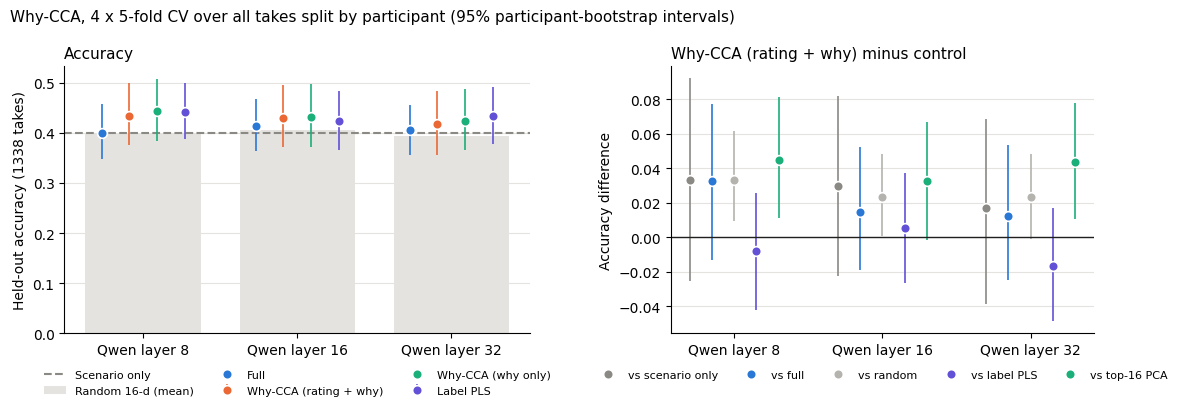

In [6]:
import matplotlib.pyplot as plt

COLORS = {"full": "#2a78d6", "why-CCA (rating + why)": "#eb6834", "why-CCA (why only)": "#1baf7a", "label PLS": "#6250d6"}
NULL_COLOR, GRID_COLOR, BAND_COLOR = "#8a8984", "#e4e3df", "#e4e3df"

def style(ax):
    ax.grid(axis="y", color=GRID_COLOR, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

layers = list(LAYERS.values())
x = np.arange(len(layers))
fig, (ax, ax_diff) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
all_rows = SUBGROUPS["All"]
ax.bar(x, [per_take[f"layer {l}: random"].mean() for l in layers], width=0.75, color=BAND_COLOR, label="Random 16-d (mean)")
ax.axhline(per_take["scenario only"].mean(), color=NULL_COLOR, lw=1.5, ls="--", label="Scenario only")
offsets = dict(zip(COLORS, np.linspace(-0.27, 0.27, len(COLORS))))
for method, color in COLORS.items():
    stats = np.array([describe(per_take[f"layer {l}: {method}"], all_rows) for l in layers])
    ax.errorbar(x + offsets[method], stats[:, 0], yerr=[stats[:, 0] - stats[:, 1], stats[:, 2] - stats[:, 0]], ls="none",
                marker="o", ms=7, color=color, markeredgecolor="white", markeredgewidth=1.2, elinewidth=1.2, capsize=0,
                label=method.replace("why-CCA", "Why-CCA").replace("full", "Full").replace("label", "Label"))
ax.set_xticks(x, [f"Qwen layer {l}" for l in layers])
ax.set_ylabel(f"Held-out accuracy ({len(names)} takes)")
ax.set_title("Accuracy", loc="left", fontsize=11)
style(ax)

CONTROLS = ["scenario only", "full", "random", "label PLS", "top-16 PCA"]
control_colors = dict(zip(CONTROLS, ("#8a8984", "#2a78d6", "#b5b3ad", "#6250d6", "#1baf7a")))
offsets = dict(zip(CONTROLS, np.linspace(-0.3, 0.3, len(CONTROLS))))
for control in CONTROLS:
    stats = np.array([differences[l, control] for l in layers])
    ax_diff.errorbar(x + offsets[control], stats[:, 0], yerr=[stats[:, 0] - stats[:, 1], stats[:, 2] - stats[:, 0]], ls="none",
                     marker="o", ms=7, color=control_colors[control], markeredgecolor="white", markeredgewidth=1.2,
                     elinewidth=1.2, capsize=0, label=f"vs {control}")
ax_diff.axhline(0, color="#1f1f1d", lw=1)
ax_diff.set_xticks(x, [f"Qwen layer {l}" for l in layers])
ax_diff.set_ylabel("Accuracy difference")
ax_diff.set_title("Why-CCA (rating + why) minus control", loc="left", fontsize=11)
style(ax_diff)
for a, n in ((ax, 3), (ax_diff, 5)):
    a.legend(frameon=False, fontsize=8, ncol=n, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.suptitle(f"Why-CCA, {N_REPEATS} x {N_FOLDS}-fold CV over all takes split by participant "
             "(95% participant-bootstrap intervals)", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/why_cca_cv.png", dpi=200, bbox_inches="tight")
plt.show()